# PrecisionSkin: training and evaluation record of the Acne and Hyperpigmentation lesion detectors

**What this notebook is.** A documentation and evidence notebook for the thesis panel. It collects, in one place, the records that the real training runs left on the researcher's computer (run folders, per-epoch `results.csv`, `args.yaml`, experiment registry, logs, box-tool labeling logs, stored test results) and re-evaluates the finished models.

**What this notebook is not.**
- It is **not** the notebook in which the models were trained, and it was **created after training** (the date it was generated and run is printed below). It does not claim otherwise.
- It contains **no training code**. It does not retrain, fine-tune, overwrite, modify or replace any model, label or dataset. Everything it shows is read from files, or re-computed from the finished models on existing photos.
- Where a record is missing, it says **MISSING** instead of filling the gap.

**How to read it.** Section 1 states who did what. Sections 2-7 are the evidence, one block per condition. Section 8 lists everything that is missing or limited. Section 9 gives commands that let anyone check the files themselves.

*Dates in this notebook are file-system timestamps and log timestamps. They are evidence, but they are not signed or tamper-proof records.*

## 0. Environment of this run and of the original training

In [1]:
import os, sys, json, glob, re, time, datetime, hashlib, platform, warnings, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", None); pd.set_option("display.width", 230); pd.set_option("display.max_colwidth", 100)
HOME = Path.home() / "PrecisionSkinV1"; REPO = Path("/mnt/c/Users/Bautista/source/repos/SkinDevApp"); DL = Path("/mnt/c/Users/Bautista/Downloads/PrecisionSkin")
EXP = HOME / "lesion_experiments"; RUNS = EXP / "runs"; ACNE_RUN = HOME / "runs" / "lesion_acne_boxed_only"; ACNE_DS = DL / "Acne_Boxing" / "acne_dataset_v4"; MODEL_DIR = REPO / "SkinDevApp" / "Model"
MISSING = []
def missing(what): MISSING.append(what); print("MISSING:", what)
def fdate(p):
    try: return datetime.datetime.fromtimestamp(Path(p).stat().st_mtime).strftime("%Y-%m-%d %H:%M")
    except Exception: return "n/a"
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
import torch, ultralytics
print("This notebook was generated and run on:", datetime.datetime.now().strftime("%Y-%m-%d %H:%M"))
print("Python", platform.python_version(), "|", platform.platform()[:60]); print("torch", torch.__version__, "| ultralytics", ultralytics.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("\nLines recorded by the ORIGINAL training runs in the experiment queue logs (library and hardware at training time):")
seen = {}
for lg in sorted(EXP.glob("queue*.log")):
    try:
        for line in open(lg, encoding="utf-8", errors="ignore"):
            m = re.search(r"Ultralytics [\d.]+ .*?CUDA:0 \(.*?\)", line.replace("\r", "\n"))
            if m: seen.setdefault(m.group(0), []).append(lg.name); break
    except Exception: pass
for k, v in seen.items(): print("  ", k, "  <-", ", ".join(sorted(set(v)))[:140])
if not seen: missing("no training-time library line found in the queue logs")

This notebook was generated and run on: 2026-10-16 14:42
Python 3.11.16 | Linux-6.18.33.2-microsoft-standard-WSL2-x86_64-with-glibc2.4
torch 2.14.1+cu130 | ultralytics 8.4.171 | GPU: NVIDIA GeForce RTX 4060 Laptop GPU

Lines recorded by the ORIGINAL training runs in the experiment queue logs (library and hardware at training time):
   Ultralytics 8.4.171 🚀 Python-3.11.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)   <- queue.log, queue_A7_fixlabels.log, queue_acne.log, queue_acne_c.log, queue_hyp_h25seeds.log, queue_hyp_seeds.log, queue_hyp_tonight.log, que


## 1. Who did what (read this first)

This table states, as plainly as the records allow, which part of the work was done by whom. It was written from the project working records and **the researcher should confirm each row before presenting it**.

| Work | Done by | Evidence in this notebook |
|---|---|---|
| Collecting and boxing the photos: the acne dataset (training, validation, test, independent and fresh test sets), the hyperpigmentation labels under the first rule and under rule v2, the blind re-box passes, the clear-skin photos | **The researcher** (annotator "Elaiza"), with the project's box tool; model drafts were sometimes pre-drawn and then corrected by the researcher | the box tool's `labeling_log.csv` files (section 2) |
| Final acne 3-seed training (the installed acne models) | **The researcher**, by running the notebook "Pipeline V5 - Lesion Detector" in VS Code on 10 Oct 2026 | the run folder `runs/lesion_acne_boxed_only` and its timestamps (section 4), and the **executed notebook saved with its full console output** (section 4.3) |
| Acne experiments A0-A7 and C1-C3, hyperpigmentation experiments H0-H25 (including the final hyperpigmentation training) | An **AI coding assistant (Claude Code)** working in the researcher's repository, executing the scripts and notebooks on the researcher's computer, at the researcher's request | `EXPERIMENTS.csv`, queue logs, run folders (sections 4-5) |
| Acne Phase 1 experiments (E1-E4) and the scoring of the fresh acne test set | **The researcher**, running the notebooks in VS Code | run folders, lock files (sections 5, 6) |
| Acne Phase 2 candidate (960 px, 3 seeds) | The AI assistant, executing the notebook headlessly | run folders |
| Design of the pipeline, scripts, notebooks, analyses and write-ups | Built **with the help of an AI coding assistant** | git history of the repository |

The researcher is responsible for the data, the decisions and the claims; the assistant wrote and ran much of the code. Panel members should be told this in the same words.

## Helper functions
The same box-matching and scoring functions as the project's other notebooks (nothing here trains).

In [2]:
import json, csv, os, sys, time, shutil, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
warnings.filterwarnings("ignore")
EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

def rd(p):
    p = Path(p); return [tuple(map(float, l.split()[1:5])) for l in p.read_text().splitlines() if len(l.split()) >= 5] if p.exists() else []
def xyxy(b): return b[0] - b[2] / 2, b[1] - b[3] / 2, b[0] + b[2] / 2, b[1] + b[3] / 2
def iou(a, b):
    a, b = xyxy(a), xyxy(b); iw, ih = max(0, min(a[2], b[2]) - max(a[0], b[0])), max(0, min(a[3], b[3]) - max(a[1], b[1])); i = iw * ih
    return i / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i + 1e-12)
def side(b): return (b[2] * b[3]) ** 0.5
def images_of(d): return sorted(p for p in (Path(d) / "images").glob("*") if p.suffix.lower() in EXT)

def raw_preds(weights, d, imgsz=800):
    """all boxes down to confidence 0.001 for every photo of folder d (normalised x-centre, y-centre, w, h)"""
    from ultralytics import YOLO
    import torch
    m = YOLO(str(weights)); dev = 0 if torch.cuda.is_available() else "cpu"; out = {}; ims = images_of(d)
    bs = 1 if str(weights).lower().endswith(".onnx") else 8          # exported ONNX files have a fixed batch of 1
    for s in range(0, len(ims), bs):
        ch = ims[s:s + bs]
        for p, r in zip(ch, m.predict([str(x) for x in ch], imgsz=imgsz, conf=0.001, iou=0.6, max_det=300, verbose=False, device=dev)):
            out[p.name] = [(tuple(map(float, b)), float(c)) for b, c in zip(r.boxes.xywhn.cpu().numpy(), r.boxes.conf.cpu().numpy())] if len(r.boxes) else []
    return out

def fuse(lists, thr=0.5):
    """weighted box fusion: boxes of the models that overlap (IoU >= thr) become one box; confidence = sum of confidences / number of models"""
    n = len(lists); allb = sorted([b for l in lists for b in l], key=lambda x: -x[1]); clusters = []
    for b, c in allb:
        for cl in clusters:
            if iou(cl["box"], b) >= thr:
                cl["m"].append((b, c)); w = np.array([x[1] for x in cl["m"]]); cl["box"] = tuple(np.average(np.array([x[0] for x in cl["m"]]), axis=0, weights=w)); break
        else: clusters.append({"box": b, "m": [(b, c)]})
    return [(cl["box"], min(1.0, sum(x[1] for x in cl["m"]) / n)) for cl in clusters]

def _ap(conf, tp, n_gt):
    if n_gt == 0 or len(conf) == 0: return 0.0
    o = np.argsort(-conf); tp = tp[o]; tpc = np.cumsum(tp); fpc = np.cumsum(1 - tp); rec = tpc / n_gt; prec = tpc / (tpc + fpc)
    mrec = np.concatenate([[0], rec, [1]]); mpre = np.concatenate([[1], prec, [0]]); mpre = np.flip(np.maximum.accumulate(np.flip(mpre))); x = np.linspace(0, 1, 101)
    return float(np.trapezoid(np.interp(x, mrec, mpre), x)) if hasattr(np, "trapezoid") else float(np.trapz(np.interp(x, mrec, mpre), x))

def match_flags(gt, pr, thr):
    """greedy by confidence: returns (confidences, 1/0 true-positive flags) of every predicted box of one photo"""
    used = set(); cs, fl = [], []
    for b, c in sorted(pr, key=lambda x: -x[1]):
        best, bj = 0, -1
        for j, g in enumerate(gt):
            if j in used: continue
            v = iou(g, b)
            if v > best: best, bj = v, j
        ok = bj >= 0 and best >= thr
        if ok: used.add(bj)
        cs.append(c); fl.append(1.0 if ok else 0.0)
    return cs, fl

def score(preds, d):
    """mAP@0.5, mAP@0.5:0.95 and the raw arrays for precision / recall / F1 at any confidence (ground truth = labels of folder d)"""
    d = Path(d); gts = {k: rd(d / "labels" / (Path(k).stem + ".txt")) for k in preds}; n_gt = sum(len(g) for g in gts.values()); aps = []; conf50 = tp50 = None
    for t in np.arange(0.5, 0.96, 0.05):
        cs, fl = [], []
        for k, pr in preds.items():
            c, f = match_flags(gts[k], pr, t); cs += c; fl += f
        cs, fl = np.array(cs), np.array(fl); aps.append(_ap(cs, fl, n_gt))
        if abs(t - 0.5) < 1e-9: conf50, tp50 = cs, fl
    return dict(AP50=aps[0], AP50_95=float(np.mean(aps)), conf=conf50, tp=tp50, n_gt=n_gt)

def at_conf(s, c):
    m = s["conf"] >= c; tp = s["tp"][m].sum(); p = tp / max(1, m.sum()); r = tp / max(1, s["n_gt"]); return p, r, 2 * p * r / max(1e-9, p + r)

def best_conf(s):
    cs = np.arange(0.05, 0.9, 0.025); return float(max(cs, key=lambda c: at_conf(s, c)[2]))

def rows_at(preds, d, thr):
    """per photo: true positives, false positives, false negatives, zones of your boxes, zones of the model boxes, n your boxes, n model boxes"""
    rows = []
    for k, pr in preds.items():
        gt = rd(Path(d) / "labels" / (Path(k).stem + ".txt")); pc = [b for b, c in pr if c >= thr]; _, fl = match_flags(gt, [(b, 1.0) for b in pc], 0.5); tp = int(sum(fl))
        cell = lambda b: min(2, int(b[1] * 3)) * 3 + min(2, int(b[0] * 3))
        rows.append((tp, len(pc) - tp, len(gt) - tp, {cell(g) for g in gt}, {cell(b) for b in pc}, len(gt), len(pc)))
    return rows

def prf(rows):
    tp, fp, fn = sum(r[0] for r in rows), sum(r[1] for r in rows), sum(r[2] for r in rows); p, r = tp / max(1, tp + fp), tp / max(1, tp + fn); return p, r, 2 * p * r / max(1e-9, p + r)

def zone_f1(rows):
    tp = sum(len(r[3] & r[4]) for r in rows); fp = sum(len(r[4] - r[3]) for r in rows); fn = sum(len(r[3] - r[4]) for r in rows); return 2 * tp / max(1, 2 * tp + fp + fn)

def f1_by_iou(preds, d, thr, ious=(0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8)):
    out = {}
    for t in ious:
        tp = fp = fn = 0
        for k, pr in preds.items():
            gt = rd(Path(d) / "labels" / (Path(k).stem + ".txt")); pc = [(b, 1.0) for b, c in pr if c >= thr]; _, fl = match_flags(gt, pc, t); x = int(sum(fl)); tp += x; fp += len(pc) - x; fn += len(gt) - x
        p, r = tp / max(1, tp + fp), tp / max(1, tp + fn); out[t] = 2 * p * r / max(1e-9, p + r)
    return out

def bootstrap_f1(rows, n=1000, seed=0):
    rng = np.random.default_rng(seed); idx = np.arange(len(rows)); b = [prf([rows[i] for i in rng.choice(idx, len(idx))])[2] for _ in range(n)]; return float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))

def show_examples(preds, d, thr, names, cols=4, title=""):
    d = Path(d); fig, ax = plt.subplots(-(-len(names) // cols), cols, figsize=(4 * cols, 4 * -(-len(names) // cols))); ax = np.array(ax).reshape(-1)
    for a in ax: a.axis("off")
    for a, n in zip(ax, names):
        p = next(iter((d / "images").glob(Path(n).stem + ".*"))); im = Image.open(p).convert("RGB"); W, H = im.size; dr = ImageDraw.Draw(im); lw = max(2, W // 250)
        for b in rd(d / "labels" / (Path(n).stem + ".txt")): x0, y0, x1, y1 = xyxy(b); dr.rectangle([x0 * W, y0 * H, x1 * W, y1 * H], outline=(40, 220, 60), width=lw)
        for b, c in preds[n]:
            if c >= thr: x0, y0, x1, y1 = xyxy(b); dr.rectangle([x0 * W, y0 * H, x1 * W, y1 * H], outline=(255, 40, 40), width=lw)
        a.imshow(im); a.set_title(n[:28], fontsize=8)
    fig.suptitle(title + "  (green = your boxes, red = model boxes above the threshold)"); plt.tight_layout(); plt.show()

def curves(run_dirs, labels):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for rd_, lb in zip(run_dirs, labels):
        f = Path(rd_) / "results.csv"
        if not f.exists(): continue
        r = pd.read_csv(f); r.columns = [c.strip() for c in r.columns]
        ax[0].plot(r["epoch"], r["train/box_loss"], label=lb + " train"); ax[0].plot(r["epoch"], r["val/box_loss"], "--", label=lb + " val")
        ax[1].plot(r["epoch"], r["metrics/mAP50(B)"], label=lb); ax[2].plot(r["epoch"], r["metrics/mAP50-95(B)"], label=lb)
    for a, t in zip(ax, ("box loss (training = solid, validation = dashed)", "validation mAP@0.5", "validation mAP@0.5:0.95")): a.set_title(t, fontsize=10); a.set_xlabel("epoch"); a.legend(fontsize=7); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

## 2. Dataset preparation and annotation process

**Annotation process (from the project documents, `docs` folders of the repository).**
- *Acne:* individual spots are boxed one box per visible spot with the project's box tool. Many photos were first pre-drawn by a helper model and then corrected photo by photo by the researcher. The annotation audit (`acne/docs/ACNE_IMPROVEMENT_AUDIT_AND_PLAN.md`) found individual lesions (not grouped regions) and measured the researcher's agreement with their own earlier boxes.
- *Hyperpigmentation:* first boxed under a loose rule (agreement of the researcher with their own boxes F1 0.28 at IoU 0.5), then a stricter written rule v2 (`hyperpigmentation/docs/HYPERPIGMENTATION_ANNOTATION_RULE_V2.md`) with blind re-box passes and hand correction of the training photos.
The numbers below are **re-computed from the label files now**.

In [3]:
def split_stats(name, d):
    d = Path(d)
    if not (d / "images").exists(): missing("dataset folder " + str(d)); return None
    ims = images_of(d); nb = [len(rd(d / "labels" / (p.stem + ".txt"))) for p in ims]; sd = [side(b) for p in ims for b in rd(d / "labels" / (p.stem + ".txt"))]
    return dict(set=name, photos=len(ims), photos_without_boxes=sum(1 for x in nb if x == 0), boxes=sum(nb), boxes_per_photo=round(float(np.mean(nb)), 1), median_box_side=round(float(np.median(sd)), 3) if sd else None, folder=str(d))
print("ACNE dataset v4 and the later sets"); A = [split_stats("train", ACNE_DS / "train"), split_stats("validation", ACNE_DS / "val"), split_stats("development test", ACNE_DS / "test"),
     split_stats("independent set (41 photos)", DL / "Acne_Boxing" / "Independent_Final_Set" / "boxed_independent"), split_stats("fresh test (boxed from scratch)", EXP / "data" / "acne_fresh_test")]
display(pd.DataFrame([a for a in A if a]))
print("\nHYPERPIGMENTATION (annotation rule v2)")
tl = RUNS / "H25_v2human_all_pub" / "train_list.txt"
if tl.exists():
    lst = [l.strip() for l in tl.read_text().splitlines() if l.strip()]; own = [p for p in lst if "hyp_v2human_only" in p]
    print("training list of the final run: %d images = %d images from the researcher's corrected photos (each photo listed 3 times: original and 2 copies, i.e. about %d photos) + %d public photos" % (len(lst), len(own), len(set(Path(p).name.split("_rep")[0] for p in own)), len(lst) - len(own)))
else: missing("training list of the final hyperpigmentation run")
H = [split_stats("validation (60 photos, rule v2)", EXP / "data" / "hyp_v2_val60"), split_stats("test (100 photos, rule v2, boxed from scratch)", EXP / "data" / "hyp_v2_test")]
display(pd.DataFrame([h for h in H if h]))

ACNE dataset v4 and the later sets


,set,photos,photos_without_boxes,boxes,boxes_per_photo,median_box_side,folder
0,train,1145,0,11621,10.1,0.064,/mnt/c/Users/Bautista/Downloads/PrecisionSkin/Acne_Boxing/acne_dataset_v4/train
1,validation,154,0,1562,10.1,0.058,/mnt/c/Users/Bautista/Downloads/PrecisionSkin/Acne_Boxing/acne_dataset_v4/val
2,development test,167,0,1369,8.2,0.060,/mnt/c/Users/Bautista/Downloads/PrecisionSkin/Acne_Boxing/acne_dataset_v4/test
3,independent set (41 photos),41,0,437,10.7,0.058,/mnt/c/Users/Bautista/Downloads/PrecisionSkin/Acne_Boxing/Independent_Final_Set/boxed_independent
4,fresh test (boxed from scratch),100,64,203,2.0,0.053,/home/bautista/PrecisionSkinV1/lesion_experiments/data/acne_fresh_test



HYPERPIGMENTATION (annotation rule v2)
training list of the final run: 3684 images = 2424 images from the researcher's corrected photos (each photo listed 3 times: original and 2 copies, i.e. about 1616 photos) + 1260 public photos


,set,photos,photos_without_boxes,boxes,boxes_per_photo,median_box_side,folder
0,"validation (60 photos, rule v2)",60,3,142,2.4,0.257,/home/bautista/PrecisionSkinV1/lesion_experiments/data/hyp_v2_val60
1,"test (100 photos, rule v2, boxed from scratch)",100,2,226,2.3,0.255,/home/bautista/PrecisionSkinV1/lesion_experiments/data/hyp_v2_test


### 2.1 Manual boxing activity recorded by the box tool
The box tool writes a `labeling_log.csv` next to every labelling folder: one row per saved photo with the time it was saved, the annotator name, the number of boxes and the seconds spent. This is the strongest available evidence that the boxes were drawn by hand. (`seconds` is the active time the tool measured for that photo.)

In [4]:
rows = []
for cond, base in (("acne", DL / "Acne_Boxing"), ("hyperpigmentation", DL / "Hyperpigmentation_Boxing")):
    for f in sorted(base.rglob("labeling_log.csv")):
        try:
            d = pd.read_csv(f); d["timestamp"] = pd.to_datetime(d["timestamp"]); s = d[d["action"].isin(["save", "none", "x", "empty"])] if "action" in d else d
            rows.append(dict(condition=cond, folder=str(f.parent.parent.relative_to(base)), photos_logged=d["image"].nunique(), saved_actions=len(d), boxes_saved=int(d["n_boxes"].sum()), active_minutes=round(float(d["seconds"].sum()) / 60, 1),
                             first=d["timestamp"].min().strftime("%Y-%m-%d %H:%M"), last=d["timestamp"].max().strftime("%Y-%m-%d %H:%M"), annotator=",".join(sorted(d["annotator"].astype(str).unique()))))
        except Exception as e: missing("could not read " + str(f) + " (" + str(e)[:50] + ")")
LOG = pd.DataFrame(rows); display(LOG)
for cond in ("acne", "hyperpigmentation"):
    s = LOG[LOG.condition == cond]
    if len(s): print("%-18s %d labelling folders | %d photo records | %d box-count total over all saves (includes boxes pre-drawn by a helper model and kept by the researcher; a photo saved twice counts twice) | about %.1f hours of active tool time | between %s and %s" % (cond, len(s), s.photos_logged.sum(), s.boxes_saved.sum(), s.active_minutes.sum() / 60, s["first"].min(), s["last"].max()))

,condition,folder,photos_logged,saved_actions,boxes_saved,active_minutes,first,last,annotator
0,acne,Acne_Fresh_Test,100,102,215,8.8,2026-10-15 21:42,2026-10-15 21:51,Elaiza
1,acne,Acne_New_Photos,250,262,3061,40.5,2026-10-13 17:23,2026-10-13 18:17,Elaiza
2,acne,Acne_Review_Missing,111,119,2266,7.4,2026-10-13 18:18,2026-10-13 18:25,Elaiza
3,acne,Draft_Acne,841,875,9045,113.5,2026-10-09 15:40,2026-10-10 00:05,Elaiza
4,acne,.,927,980,6333,373.8,2026-10-06 19:33,2026-10-09 19:11,Elaiza
5,acne,Fix_46_Doubled_Boxes,46,49,766,3.8,2026-10-09 22:28,2026-10-09 22:33,Elaiza
6,acne,Fix_6_Test_Photos,6,6,12,0.8,2026-10-09 19:44,2026-10-09 19:45,Elaiza
7,acne,Fix_Acne_Missed_Spots,60,63,1598,11.3,2026-10-10 19:05,2026-10-10 19:15,Elaiza
8,acne,Independent_Final_Set,43,46,447,25.8,2026-10-10 20:07,2026-10-10 20:32,Elaiza
9,acne,More_Faces,580,611,4893,107.9,2026-10-10 11:02,2026-10-10 13:34,Elaiza


acne               12 labelling folders | 3072 photo records | 29287 box-count total over all saves (includes boxes pre-drawn by a helper model and kept by the researcher; a photo saved twice counts twice) | about 12.3 hours of active tool time | between 2026-10-06 19:33 and 2026-10-15 21:51
hyperpigmentation  11 labelling folders | 1744 photo records | 6262 box-count total over all saves (includes boxes pre-drawn by a helper model and kept by the researcher; a photo saved twice counts twice) | about 5.7 hours of active tool time | between 2026-10-10 09:49 and 2026-10-13 17:16


## 3. Model architecture and training configuration (read from `args.yaml` of the real runs)
Both detectors are the **official Ultralytics YOLOv8s** (small) model, starting from the COCO-pretrained `yolov8s.pt`, one class each, trained with three random seeds. The configuration below is read from each run's own `args.yaml` (the settings Ultralytics itself recorded when the run started).

In [5]:
import yaml
KEYS = ["model", "imgsz", "epochs", "patience", "batch", "optimizer", "lr0", "cos_lr", "close_mosaic", "seed", "deterministic", "amp", "workers", "fliplr", "degrees", "scale", "mosaic", "hsv_h", "hsv_s", "hsv_v", "data"]
def read_args(run):
    f = Path(run) / "args.yaml"
    if not f.exists(): missing("args.yaml of " + str(run)); return None
    a = yaml.safe_load(open(f)); r = {k: a.get(k) for k in KEYS}; r["run"] = Path(run).name; r["args.yaml written"] = fdate(f); r["data"] = Path(str(r["data"])).name; return r
ACNE_SEEDS = {s: ACNE_RUN / "models" / ("seed_%d" % s) for s in (123, 42, 7)}
HYP_RUNS = {42: RUNS / "H25_v2human_all_pub", 7: RUNS / "H25_s7", 123: RUNS / "H25_s123"}
print("ACNE final runs (the models installed in the app):"); display(pd.DataFrame([r for r in (read_args(p) for p in ACNE_SEEDS.values()) if r]).set_index("run").T)
print("\nHYPERPIGMENTATION final runs (H25, the models installed in the app):"); display(pd.DataFrame([r for r in (read_args(p) for p in HYP_RUNS.values()) if r]).set_index("run").T)
from ultralytics import YOLO
for name, w in (("acne seed 123", ACNE_SEEDS[123] / "weights" / "best.pt"), ("hyperpigmentation seed 42", HYP_RUNS[42] / "weights" / "best.pt")):
    if Path(w).exists():
        mm = YOLO(str(w)).model; npar = sum(q.numel() for q in mm.parameters())
        try:
            from ultralytics.utils.torch_utils import get_flops; gf = "%.1f" % get_flops(mm, 800)
        except Exception: gf = "n/a"
        print("%-26s architecture %s | trainable parameters %s | GFLOPs at 800 px %s | modules %d" % (name, type(mm).__name__, "{:,}".format(npar), gf, len(list(mm.modules()))))
    else: missing("weights of " + name)

ACNE final runs (the models installed in the app):


run,seed_123,seed_42,seed_7
model,yolov8s.pt,yolov8s.pt,yolov8s.pt
imgsz,800,800,800
epochs,100,100,100
patience,30,30,30
batch,8,8,8
optimizer,auto,auto,auto
lr0,0.01,0.01,0.01
cos_lr,True,True,True
close_mosaic,10,10,10
seed,123,42,7



HYPERPIGMENTATION final runs (H25, the models installed in the app):


run,H25_v2human_all_pub,H25_s7,H25_s123
model,/home/bautista/PrecisionSkinV1/lesion_experiments/runs/H25_v2human_all_pub/weights/last.pt,yolov8s.pt,yolov8s.pt
imgsz,800,800,800
epochs,100,100,100
patience,100,30,30
batch,8,8,8
optimizer,AdamW,AdamW,AdamW
lr0,0.0005,0.0005,0.0005
cos_lr,True,True,True
close_mosaic,10,10,10
seed,42,7,123


acne seed 123              architecture DetectionModel | trainable parameters 11,135,987 | GFLOPs at 800 px 44.8 | modules 225
hyperpigmentation seed 42  architecture DetectionModel | trainable parameters 11,135,987 | GFLOPs at 800 px 44.8 | modules 225


## 4. Training history of the final runs (per-epoch records written by Ultralytics during the real training)

In [6]:
def history(title, runs):
    print("=" * 110); print(title); out = []
    for s, run in runs.items():
        f = Path(run) / "results.csv"
        if not f.exists(): missing("results.csv of %s seed %s" % (title, s)); continue
        r = pd.read_csv(f); r.columns = [c.strip() for c in r.columns]; b = r["metrics/mAP50(B)"].idxmax(); w = Path(run) / "weights" / "best.pt"
        out.append(dict(seed=s, epochs_trained=len(r), best_epoch_by_mAP50=int(r.loc[b, "epoch"]), best_val_mAP50=round(r.loc[b, "metrics/mAP50(B)"], 3), best_val_mAP50_95=round(r.loc[b, "metrics/mAP50-95(B)"], 3),
                        P_at_best=round(r.loc[b, "metrics/precision(B)"], 3), R_at_best=round(r.loc[b, "metrics/recall(B)"], 3), training_minutes=round(float(r["time"].iloc[-1]) / 60, 1),
                        results_csv_dated=fdate(f), best_pt_dated=fdate(w) if w.exists() else "weights not found", best_pt_bytes=w.stat().st_size if w.exists() else None))
    display(pd.DataFrame(out))
history("ACNE: three seeds of the final training (800 px, YOLOv8s)", ACNE_SEEDS); history("HYPERPIGMENTATION: three seeds of the final training (800 px, YOLOv8s, rule-v2 labels)", HYP_RUNS)

ACNE: three seeds of the final training (800 px, YOLOv8s)


,seed,epochs_trained,best_epoch_by_mAP50,best_val_mAP50,best_val_mAP50_95,P_at_best,R_at_best,training_minutes,results_csv_dated,best_pt_dated,best_pt_bytes
0,123,85,32,0.430,0.134,0.486,0.472,29.5,2026-10-10 22:32,2026-10-10 22:32,22524330
1,42,100,78,0.432,0.139,0.488,0.509,34.2,2026-10-10 21:36,2026-10-10 21:36,22526250
2,7,79,50,0.424,0.134,0.514,0.460,26.4,2026-10-10 22:02,2026-10-10 22:02,22523562


HYPERPIGMENTATION: three seeds of the final training (800 px, YOLOv8s, rule-v2 labels)


,seed,epochs_trained,best_epoch_by_mAP50,best_val_mAP50,best_val_mAP50_95,P_at_best,R_at_best,training_minutes,results_csv_dated,best_pt_dated,best_pt_bytes
0,42,100,47,0.475,0.163,0.530,0.472,52.5,2026-10-13 13:42,2026-10-13 13:42,22554538
1,7,66,32,0.480,0.172,0.521,0.500,64.1,2026-10-13 14:56,2026-10-13 14:56,22550186
2,123,55,21,0.474,0.177,0.617,0.423,53.5,2026-10-13 15:57,2026-10-13 15:57,22548778


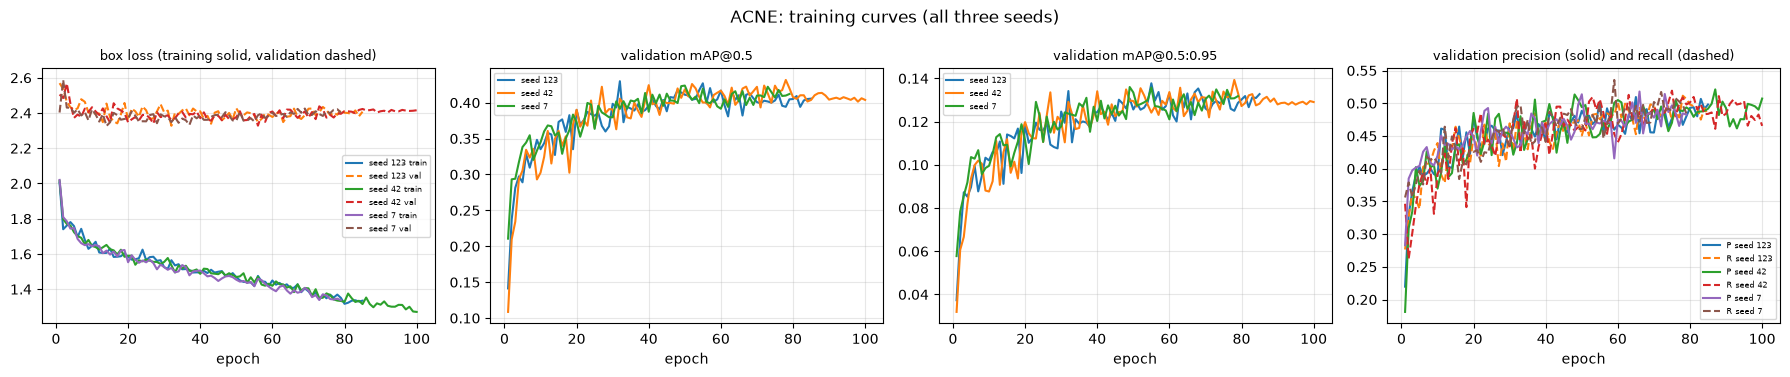

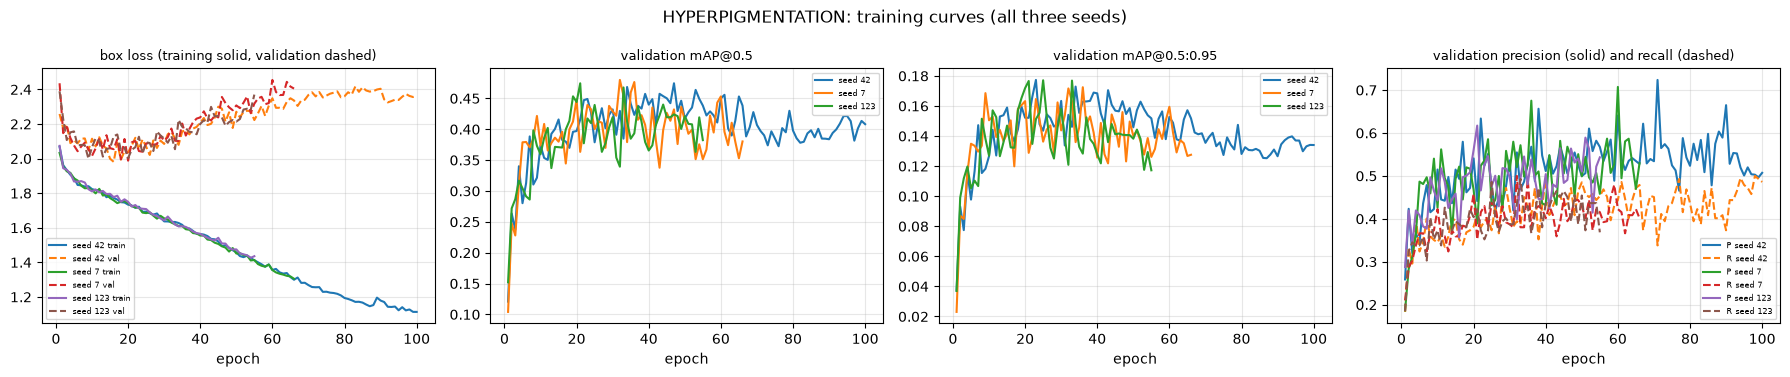

In [7]:
def curves_for(title, runs):
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
    for s, run in runs.items():
        f = Path(run) / "results.csv"
        if not f.exists(): continue
        r = pd.read_csv(f); r.columns = [c.strip() for c in r.columns]
        ax[0].plot(r["epoch"], r["train/box_loss"], label="seed %s train" % s); ax[0].plot(r["epoch"], r["val/box_loss"], "--", label="seed %s val" % s)
        ax[1].plot(r["epoch"], r["metrics/mAP50(B)"], label="seed %s" % s); ax[2].plot(r["epoch"], r["metrics/mAP50-95(B)"], label="seed %s" % s)
        ax[3].plot(r["epoch"], r["metrics/precision(B)"], label="P seed %s" % s); ax[3].plot(r["epoch"], r["metrics/recall(B)"], "--", label="R seed %s" % s)
    for a, t in zip(ax, ("box loss (training solid, validation dashed)", "validation mAP@0.5", "validation mAP@0.5:0.95", "validation precision (solid) and recall (dashed)")): a.set_title(t, fontsize=9); a.set_xlabel("epoch"); a.legend(fontsize=6); a.grid(alpha=.3)
    fig.suptitle(title); plt.tight_layout(); plt.show()
curves_for("ACNE: training curves (all three seeds)", ACNE_SEEDS); curves_for("HYPERPIGMENTATION: training curves (all three seeds)", HYP_RUNS)

### 4.1 Plots and confusion matrices saved by Ultralytics during the real runs
These images were written by the training library itself at the time of the runs. If an image was not saved, it says MISSING.

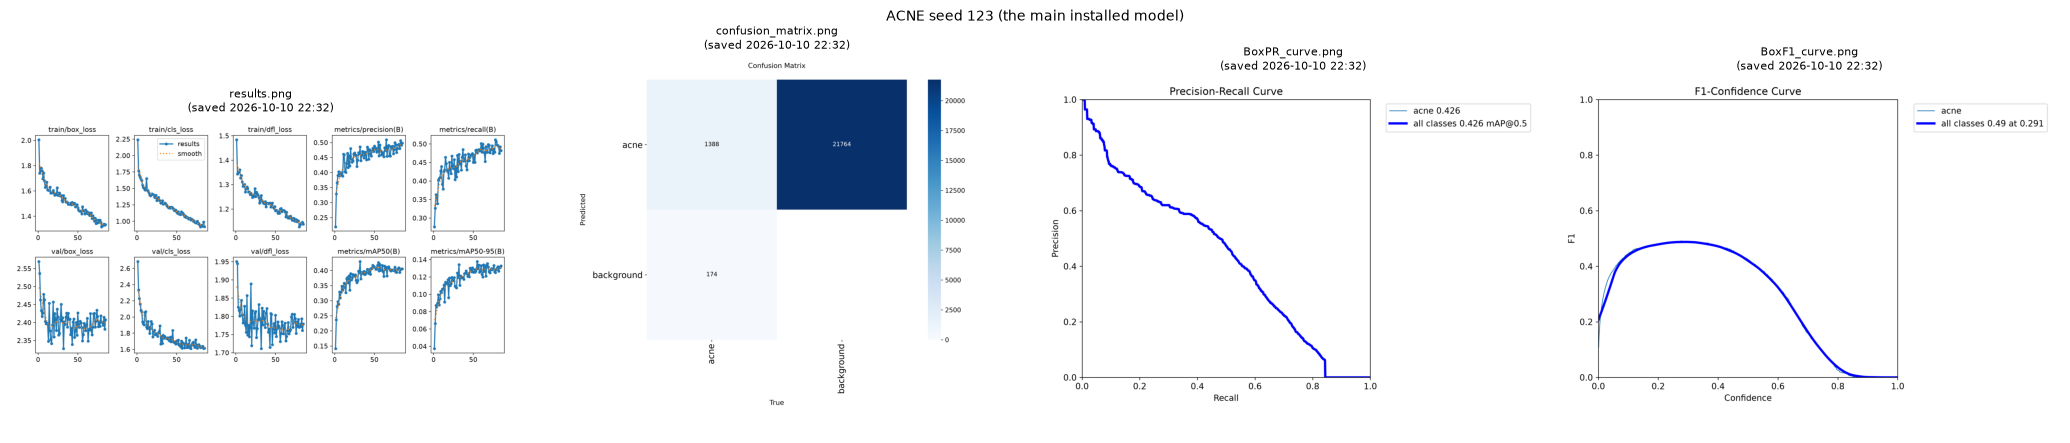

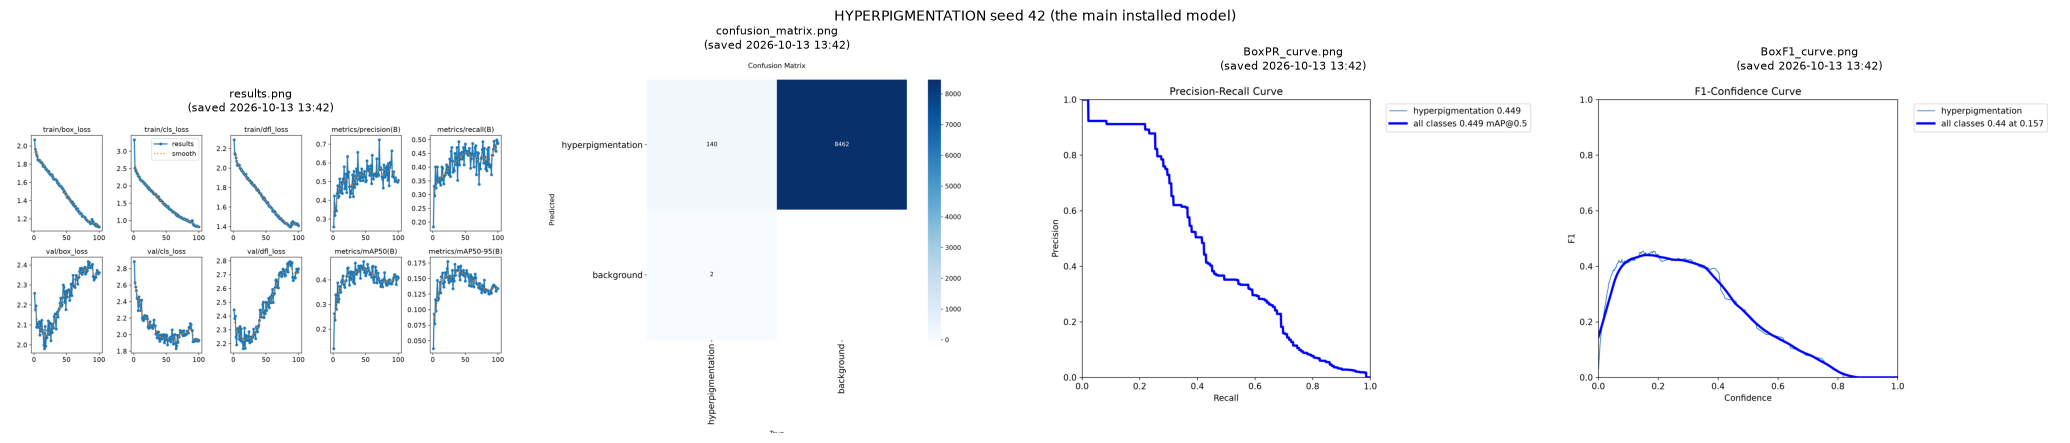

Note: Ultralytics' confusion matrix for a one-class detector has the classes 'acne' / 'hyperpigmentation' and 'background'; the detection counts (found / false / missed) at the chosen threshold are computed in section 7.


In [8]:
def show_pngs(title, run, names):
    fig, ax = plt.subplots(1, len(names), figsize=(5.2 * len(names), 4.6))
    for a, n in zip(np.atleast_1d(ax), names):
        a.axis("off"); p = Path(run) / n
        if p.exists(): a.imshow(Image.open(p)); a.set_title("%s\n(saved %s)" % (n, fdate(p)), fontsize=8)
        else: a.text(0.5, 0.5, "MISSING\n" + n, ha="center"); missing("%s: %s" % (title, n))
    fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()
NAMES = ["results.png", "confusion_matrix.png", "BoxPR_curve.png", "BoxF1_curve.png"]
show_pngs("ACNE seed 123 (the main installed model)", ACNE_SEEDS[123], NAMES); show_pngs("HYPERPIGMENTATION seed 42 (the main installed model)", HYP_RUNS[42], NAMES)
print("Note: Ultralytics' confusion matrix for a one-class detector has the classes 'acne' / 'hyperpigmentation' and 'background'; the detection counts (found / false / missed) at the chosen threshold are computed in section 7.")

### 4.2 Every finished epoch of every final seed (the saved `results.csv`)

In [9]:
cols = {"epoch": "epoch", "time": "elapsed_s", "train/box_loss": "box_loss", "train/cls_loss": "cls_loss", "train/dfl_loss": "dfl_loss", "metrics/precision(B)": "P", "metrics/recall(B)": "R", "metrics/mAP50(B)": "mAP50", "metrics/mAP50-95(B)": "mAP50-95", "val/box_loss": "val_box_loss"}
for title, runs in (("ACNE", ACNE_SEEDS), ("HYPERPIGMENTATION", HYP_RUNS)):
    for s, run in runs.items():
        f = Path(run) / "results.csv"
        if not f.exists(): continue
        r = pd.read_csv(f); r.columns = [c.strip() for c in r.columns]; t = r[list(cols)].rename(columns=cols); t["epoch"] = t["epoch"].astype(int); t["new best mAP50"] = np.where(t["mAP50"] == t["mAP50"].cummax(), "*", "")
        print("=" * 100); print("%s seed %s | %d epochs | file dated %s" % (title, s, len(t), fdate(f))); display(t.round(3).set_index("epoch"))

ACNE seed 123 | 85 epochs | file dated 2026-10-10 22:32


,elapsed_s,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,val_box_loss,new best mAP50
epoch,,,,,,,,,,
1,20.379,2.005,2.241,1.484,0.220,0.276,0.141,0.037,2.570,*
2,39.449,1.740,1.768,1.343,0.329,0.326,0.237,0.066,2.537,*
3,58.480,1.761,1.704,1.350,0.366,0.363,0.281,0.087,2.463,*
4,77.451,1.781,1.670,1.353,0.390,0.353,0.297,0.085,2.433,*
5,96.330,1.758,1.643,1.361,0.403,0.339,0.289,0.090,2.417,
6,115.305,1.696,1.619,1.327,0.389,0.403,0.329,0.100,2.426,*
7,135.083,1.743,1.551,1.337,0.392,0.407,0.309,0.088,2.478,
8,155.675,1.680,1.517,1.311,0.400,0.409,0.328,0.095,2.463,
9,175.351,1.629,1.502,1.294,0.392,0.427,0.348,0.103,2.403,*


ACNE seed 42 | 100 epochs | file dated 2026-10-10 21:36


,elapsed_s,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,val_box_loss,new best mAP50
epoch,,,,,,,,,,
1,22.476,2.015,2.779,1.456,0.181,0.346,0.109,0.032,2.505,*
2,45.933,1.798,1.782,1.336,0.309,0.262,0.210,0.061,2.485,*
3,66.807,1.771,1.716,1.320,0.335,0.302,0.234,0.067,2.568,*
4,86.605,1.762,1.699,1.332,0.402,0.344,0.293,0.082,2.454,*
5,106.671,1.724,1.689,1.323,0.374,0.376,0.306,0.094,2.372,*
6,127.358,1.701,1.588,1.302,0.381,0.394,0.334,0.100,2.391,*
7,146.989,1.692,1.581,1.314,0.426,0.376,0.323,0.102,2.378,
8,167.308,1.655,1.542,1.277,0.402,0.401,0.336,0.101,2.425,*
9,186.831,1.679,1.566,1.293,0.406,0.331,0.293,0.088,2.405,


ACNE seed 7 | 79 epochs | file dated 2026-10-10 22:02


...

,elapsed_s,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,val_box_loss,new best mAP50
epoch,,,,,,,,,,
1,64.618,2.068,3.333,2.291,0.259,0.183,0.121,0.037,2.258,*
2,123.609,1.962,2.511,2.151,0.423,0.331,0.264,0.093,2.176,*
3,183.002,1.933,2.440,2.137,0.320,0.296,0.237,0.077,2.196,
4,242.867,1.906,2.412,2.104,0.367,0.401,0.340,0.116,2.089,*
5,307.177,1.887,2.370,2.069,0.344,0.324,0.280,0.098,2.106,
6,371.741,1.848,2.340,2.030,0.436,0.345,0.313,0.117,2.088,
7,429.867,1.846,2.291,2.040,0.479,0.401,0.388,0.147,2.115,*
8,485.168,1.838,2.265,2.029,0.415,0.359,0.310,0.115,2.117,
9,539.965,1.840,2.246,2.031,0.423,0.351,0.321,0.118,2.049,


HYPERPIGMENTATION seed 7 | 66 epochs | file dated 2026-10-13 14:56


,elapsed_s,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,val_box_loss,new best mAP50
epoch,,,,,,,,,,
1,68.234,2.033,2.729,2.256,0.187,0.210,0.104,0.023,2.436,*
2,135.100,1.954,2.511,2.141,0.283,0.287,0.247,0.087,2.147,*
3,195.521,1.926,2.425,2.097,0.312,0.303,0.228,0.085,2.184,
4,257.271,1.918,2.405,2.100,0.365,0.338,0.311,0.116,2.119,*
5,326.004,1.886,2.347,2.058,0.487,0.366,0.379,0.135,2.076,*
6,387.659,1.873,2.328,2.039,0.481,0.366,0.379,0.134,2.043,*
7,453.975,1.843,2.253,2.006,0.497,0.324,0.371,0.130,2.070,
8,514.170,1.828,2.214,2.000,0.459,0.366,0.385,0.134,2.092,*
9,574.515,1.830,2.215,2.001,0.540,0.373,0.422,0.169,2.054,*


HYPERPIGMENTATION seed 123 | 55 epochs | file dated 2026-10-13 15:57


,elapsed_s,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,val_box_loss,new best mAP50
epoch,,,,,,,,,,
1,76.231,2.074,2.850,2.305,0.288,0.185,0.152,0.037,2.390,*
2,137.132,1.945,2.551,2.159,0.419,0.324,0.272,0.099,2.229,*
3,203.885,1.935,2.465,2.126,0.341,0.345,0.287,0.112,2.107,*
4,263.618,1.913,2.406,2.101,0.420,0.338,0.317,0.120,2.152,*
5,323.797,1.868,2.338,2.062,0.408,0.338,0.304,0.105,2.157,
6,384.266,1.867,2.325,2.055,0.382,0.357,0.291,0.110,2.076,
7,444.816,1.870,2.309,2.043,0.377,0.303,0.286,0.107,2.079,
8,505.100,1.862,2.283,2.018,0.497,0.403,0.398,0.152,2.077,*
9,565.570,1.823,2.217,2.001,0.465,0.352,0.373,0.138,2.000,


### 4.3 The executed notebook of the final acne training (saved with its console output)
The notebook **"Pipeline V5 - Lesion Detector"** was run top to bottom on the researcher's computer on 10 Oct 2026 and saved with all outputs. The saved file (copied unchanged into `acne/evidence/`; the original stays in `Downloads`) contains the complete Ultralytics console output of the three final acne trainings. Below it is opened read-only: its kernel, execution counts, configuration, and the number of epochs in its console output, which is then compared with the per-epoch `results.csv` files above.

In [10]:
EVID = REPO / "acne" / "evidence" / "Pipeline V5 - Lesion Detector__EXECUTED_by_researcher_2026-10-10.ipynb"; ORIG = Path("/mnt/c/Users/Bautista/Downloads/Pipeline V5 - Lesion Detector.ipynb")
if EVID.exists():
    nbx = json.load(open(EVID, encoding="utf-8")); cells = nbx["cells"]; ks = nbx["metadata"].get("kernelspec", {})
    print("file: %s" % EVID.name); print("   saved %s | %.0f KB | SHA-256 %s" % (fdate(ORIG if ORIG.exists() else EVID), EVID.stat().st_size / 1024, sha256(EVID)))
    print("   original in Downloads: %s (dated %s)" % (ORIG, fdate(ORIG)) if ORIG.exists() else "   original in Downloads: not found now")
    print("kernel: %s | Python %s" % (ks.get("display_name"), nbx["metadata"].get("language_info", {}).get("version")))
    codec = [c for c in cells if c["cell_type"] == "code"]; ex = [c.get("execution_count") for c in codec]
    print("code cells: %d | execution counts: %s | executed in order from 1: %s | cells with saved output: %d" % (len(codec), ex[:25], ex == sorted(ex) and ex[0] == 1, sum(1 for c in codec if c.get("outputs"))))
    def outtext(c): return "".join("".join(o.get("text", "")) for o in c.get("outputs", []) if o.get("output_type") == "stream").replace("\r", "\n")
    cfg = [outtext(c) for c in codec if "condition:" in outtext(c)]; print("\nconfiguration printed by the notebook:\n" + (cfg[0].strip() if cfg else "not found"))
    tr = max(codec, key=lambda c: len(outtext(c))); txt = outtext(tr); lines = [l for l in txt.splitlines() if l.strip()]
    print("\nthe training cell's saved console output has %d lines" % len(lines))
    ban = [l for l in lines if l.startswith("Ultralytics")]; print("library line:", re.sub(r"[^\x20-\x7e]", "?", ban[0]) if ban else "not found")
    blocks = re.split(r"=+ (seed_\d+) \| training photos: (\d+)", txt); rows = []
    for i in range(1, len(blocks), 3):
        seed, nphotos, body = blocks[i], blocks[i + 1], blocks[i + 2]; allv = re.findall(r"^\s+all\s+(\d+)\s+(\d+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)", body, re.M)
        res = ACNE_RUN / "models" / seed / "results.csv"; n_csv = len(pd.read_csv(res)) if res.exists() else None
        rows.append(dict(seed=seed, training_photos=int(nphotos), validation_lines_in_console_output=len(allv), epochs_in_results_csv=n_csv, last_validation_line=("images %s instances %s P %s R %s mAP50 %s mAP50-95 %s" % allv[-1]) if allv else None))
    display(pd.DataFrame(rows))
    print("(the validation line after the last epoch of a run is Ultralytics' final re-validation of best.pt, so the console output can show one line more than results.csv has epochs)")
    summ = [outtext(c) for c in codec if "deployment summary" in outtext(c)]; print("\nthe notebook's own final summary cell:\n" + (summ[-1].strip() if summ else "not found"))
else: missing("the executed acne final-training notebook (acne/evidence copy)")

file: Pipeline V5 - Lesion Detector__EXECUTED_by_researcher_2026-10-10.ipynb
   saved 2026-10-10 22:37 | 237 KB | SHA-256 b005e0c9b0447fab847a665719a18311502c4d069e0b5e8efc930c9d82bfe59c
   original in Downloads: /mnt/c/Users/Bautista/Downloads/Pipeline V5 - Lesion Detector.ipynb (dated 2026-10-10 22:37)
kernel: PrecisionSkinV1 Python 3.13 | Python 3.13.15
code cells: 21 | execution counts: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21] | executed in order from 1: True | cells with saved output: 21

configuration printed by the notebook:
condition: acne | run: boxed_only | model: yolov8s.pt | imgsz 800 | seeds [42, 7, 123]
dataset  : /mnt/c/Users/Bautista/Downloads/PrecisionSkin/Acne_Boxing/acne_dataset_v4
outputs  : /home/bautista/PrecisionSkinV1/runs/lesion_acne_boxed_only

the training cell's saved console output has 1233 lines
library line: Ultralytics 8.4.172 ? Python-3.13.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


,seed,training_photos,validation_lines_in_console_output,epochs_in_results_csv,last_validation_line
0,seed_42,1145,101,100,images 154 instances 1562 P 0.487 R 0.51 mAP50 0.434 mAP50-95 0.139
1,seed_7,1145,80,79,images 154 instances 1562 P 0.497 R 0.46 mAP50 0.421 mAP50-95 0.136
2,seed_123,1145,86,85,images 154 instances 1562 P 0.501 R 0.475 mAP50 0.426 mAP50-95 0.138


(the validation line after the last epoch of a run is Ultralytics' final re-validation of best.pt, so the console output can show one line more than results.csv has epochs)

the notebook's own final summary cell:
# Lesion detector - deployment summary (acne, run boxed_only)

Dataset: `/mnt/c/Users/Bautista/Downloads/PrecisionSkin/Acne_Boxing/acne_dataset_v4` | fingerprint ae51483a7b72c113
split  photos  boxes  boxes_per_photo  photos_without_boxes
train    1145  11621             10.1                     0
  val     154   1562             10.1                     0
 test     167   1369              8.2                     0

Model: yolov8s.pt, 800 px, seeds [42, 7, 123] (best on validation: 123), negatives: False

Test (test, 167 photos, never used for selection), mean over seeds: mAP@0.5 0.413 (std 0.006, 95% range 0.369-0.463) | mAP@0.5-0.95 0.123 | precision 0.427 | recall 0.543 | F1 0.478
Leak-free re-evaluation: 2 look-alike test photos removed -> mAP@0.5 0.418
INDEPENDENT set (41

## 5. The controlled experiments (the record of everything that was tried)
`EXPERIMENTS.csv` is the experiment registry written automatically by the experiment runner: one row per run per validation set, with the run's settings, a fingerprint of the training data, epochs, best epoch, minutes and the validation scores. Runs that were launched from notebooks (E1-E4, the final acne runs) are in their own run folders and logs. **The weights of superseded experiment runs were deleted on 15 Oct 2026 to free disk space; their `results.csv`, settings and the registry rows were kept** (weights of the hyperpigmentation and A-series runs also exist in the backup folder `Documents/PrecisionSkin_Training_Backup`).

In [11]:
reg = pd.read_csv(EXP / "EXPERIMENTS.csv");
def results_date(rid):
    return fdate(RUNS / rid / "results.csv") if (RUNS / rid / "results.csv").exists() else "n/a"
cols_show = ["id", "note", "train_photos", "val_set", "val_mAP50", "val_mAP50_95", "val_P", "val_R", "val_F1", "epochs_run", "best_epoch", "train_minutes"]
for cond, title in (("acne", "ACNE experiments (validation = the 154 validation photos, seed 42 unless stated)"), ("hyperpigmentation", "HYPERPIGMENTATION experiments (validation sets differ by run: see val_set; scores of different sets are not comparable)")):
    t = reg[reg.condition == cond][cols_show].copy(); t["record_dated"] = t["id"].map(results_date); t["note"] = t["note"].astype(str).str.slice(0, 95)
    print("=" * 100); print(title); display(t.round(3).reset_index(drop=True))
extra = EXP / "acne_data_comparison.csv"
if extra.exists(): print("\nAcne data-comparison runs C1-C3 (recorded by the data-comparison notebook; file dated %s):" % fdate(extra)); display(pd.read_csv(extra).round(3))
else: missing("acne_data_comparison.csv (C1-C3 comparison table)")
phase1 = [r for r in ("E1_960_lowlr", "E2_960_lowlr_newdata", "E3_mosaic_off", "E4_scale025") if (RUNS / r / "results.csv").exists()]
print("\nAcne Phase 1 runs with saved per-epoch records:", phase1)

ACNE experiments (validation = the 154 validation photos, seed 42 unless stated)


,id,note,train_photos,val_set,val_mAP50,val_mAP50_95,val_P,val_R,val_F1,epochs_run,best_epoch,train_minutes,record_dated
0,A0_base,baseline of the new protocol (= v4 seed 42),1145,val,0.425,0.136,0.486,0.503,0.494,100,78,32.3,2026-10-10 16:53
1,A1_neg,FACTOR: + 115 healthy-skin negatives,1260,val,0.431,0.137,0.490,0.485,0.487,87,57,30.0,2026-10-10 17:23
2,A2_colorsafe,"FACTOR: milder colour jitter (redness is the signal): hsv_h 0.005, hsv_s 0.3, hsv_v 0.25",1145,val,0.424,0.132,0.482,0.500,0.491,84,50,26.2,2026-10-10 17:49
3,A3_box10,"FACTOR: box-loss gain 10 (tighter localisation, helps mAP50-95)",1145,val,0.431,0.135,0.498,0.498,0.498,100,75,31.1,2026-10-10 18:20
4,A4_lowlr,FACTOR: lr0 0.0005 (val loss rises after the best epoch: overfitting),1145,val,0.433,0.136,0.452,0.518,0.483,62,32,19.5,2026-10-10 18:39
5,A5_960,FACTOR: input 960 px (small spots),1145,val,0.442,0.140,0.496,0.487,0.491,89,59,40.7,2026-10-10 19:20
6,A6_m800,FACTOR: yolov8m instead of yolov8s,1145,val,0.426,0.133,0.519,0.446,0.480,74,44,54.5,2026-10-10 20:14
7,A7_fixlabels,"FACTOR: 60 training photos relabelled (893 -> 1,430 boxes: missed spots added by you); validati",1145,val,0.439,0.140,0.471,0.547,0.506,100,67,32.8,2026-10-10 20:48
8,E1_960_lowlr,960 px + lr 0.0005 AdamW,1145,val,0.452,0.144,0.508,0.482,0.495,57,27,27.4,2026-10-13 20:43
9,E2_960_lowlr_newdata,E1 + new photos and reviewed labels,1395,val,0.441,0.138,0.516,0.495,0.505,74,44,42.1,2026-10-13 21:25


HYPERPIGMENTATION experiments (validation sets differ by run: see val_set; scores of different sets are not comparable)


,id,note,train_photos,val_set,val_mAP50,val_mAP50_95,val_P,val_R,val_F1,epochs_run,best_epoch,train_minutes,record_dated
0,H1_own,FACTOR: training data = only your boxes,614,hand_val,0.267,0.084,0.302,0.392,0.341,63,37,9.9,2026-10-10 23:38
1,H1_own,FACTOR: training data = only your boxes,614,public_val,0.070,0.021,0.146,0.172,0.158,63,37,9.9,2026-10-10 23:38
2,H6_own_drafts,FACTOR: your boxes + all reviewed drafts (two box styles mixed),895,hand_val,0.298,0.092,0.329,0.369,0.348,56,47,13.7,2026-10-10 23:53
3,H6_own_drafts,FACTOR: your boxes + all reviewed drafts (two box styles mixed),895,public_val,0.058,0.016,0.140,0.152,0.146,56,47,13.7,2026-10-10 23:53
4,H7_own_drafts_cov,"FACTOR: your boxes + only the reviewed drafts in the test-photo style (coverage <= 18 %, no box",796,hand_val,0.282,0.085,0.381,0.318,0.347,54,40,11.8,2026-10-11 00:05
5,H7_own_drafts_cov,"FACTOR: your boxes + only the reviewed drafts in the test-photo style (coverage <= 18 %, no box",796,public_val,0.071,0.020,0.173,0.138,0.154,54,40,11.9,2026-10-11 00:05
6,H0_mix,"baseline of the new protocol (same recipe as before, hand-boxed validation)",2891,hand_val,0.232,0.067,0.250,0.327,0.283,80,59,47.8,2026-10-11 00:53
7,H0_mix,"baseline of the new protocol (same recipe as before, hand-boxed validation)",2891,public_val,0.336,0.112,0.396,0.393,0.395,80,59,47.8,2026-10-11 00:53
8,H8_drafts_v2,FACTOR: your boxes + all 500+ reviewed drafts (round 2),1115,hand_val,0.296,0.093,0.327,0.373,0.348,72,50,22.1,2026-10-11 14:19
9,H8_drafts_v2,FACTOR: your boxes + all 500+ reviewed drafts (round 2),1115,public_val,0.105,0.026,0.238,0.161,0.192,72,50,22.1,2026-10-11 14:19



Acne data-comparison runs C1-C3 (recorded by the data-comparison notebook; file dated 2026-10-13 20:08):


,run,mAP50,mAP50_95,precision,recall,F1,dmAP50,adopt
0,A0 baseline (v4),0.425,0.136,0.486,0.503,0.494,0.000,NaN
1,C1_acne_new,0.439,0.139,0.497,0.496,0.497,0.014,no
2,C2_acne_new_review,0.429,0.135,0.478,0.513,0.495,0.004,no
3,C3_acne_new_review_neg,0.435,0.136,0.493,0.475,0.484,0.009,no



Acne Phase 1 runs with saved per-epoch records: ['E1_960_lowlr', 'E2_960_lowlr_newdata', 'E3_mosaic_off', 'E4_scale025']


## 6. Final model selection and the files installed in the app
Selection rule used throughout: models, thresholds and settings were chosen on the **validation** photos only; a change was adopted only if it passed a rule fixed beforehand (validation mAP@0.5 at least +0.02, precision and recall not lower by more than 0.02); test sets were scored once and stored in lock files. The decisions are documented in `acne/docs/ACNE_DETECTOR_VERDICT.md`, `acne/docs/ACNE_IMPROVEMENT_AUDIT_AND_PLAN.md` and `docs/RESULTS_FOR_PAPER.md`.
- **Acne:** the installed detector is the average of the three seeds 123 / 42 / 7 (800 px). A 960 px candidate was trained and compared on a fresh test set; it did not pass the pre-set rule, so it was **not** installed.
- **Hyperpigmentation:** the installed detector is the average of the three H25 seeds (800 px), trained on rule-v2 labels.

In [12]:
rows = []
for f in sorted(MODEL_DIR.glob("lesion_detector_*.onnx")):
    rows.append(dict(file=f.name, dated=fdate(f), size_MB=round(f.stat().st_size / 1e6, 1), sha256=sha256(f)))
display(pd.DataFrame(rows))
for cond in ("acne", "hyperpigmentation"):
    j = MODEL_DIR / ("lesion_detector_%s.json" % cond)
    if j.exists():
        d = json.load(open(j)); print("%-18s settings file (dated %s): image size %s | confidence threshold %s | NMS IoU %s | classes %s" % (cond, fdate(j), d.get("imgsz"), d.get("default_conf"), d.get("nms_iou"), d.get("classes")))
        print("%-18s note in the file: %s" % ("", str(d.get("note", ""))[:230])); print("%-18s ensemble listed in the file: %s" % ("", d.get("ensemble", "not listed")))
    else: missing("settings file " + str(j))
md_ = ACNE_RUN / "logs" / "model_metadata.json"
if md_.exists():
    d = json.load(open(md_)); main = MODEL_DIR / "lesion_detector_acne.onnx"
    print("\nAcne main model: SHA-256 recorded by the training notebook at export time =", d["onnx_sha256"]); print("                 SHA-256 of the file now in the app                    =", sha256(main) if main.exists() else "n/a")
    print("                 match:", (sha256(main) == d["onnx_sha256"]) if main.exists() else "n/a", "(the other two acne files and the hyperpigmentation files have no SHA-256 recorded at export time: MISSING record, hashes above are as of today)")
    print("                 dataset fingerprint recorded:", d.get("dataset_fingerprint", "")[:32] + "...", "| best seed:", d.get("best_seed"), "| seeds:", d.get("seeds"))
else: missing("model_metadata.json of the acne final run")

,file,dated,size_MB,sha256
0,lesion_detector_acne.onnx,2026-10-11 13:49,44.8,2f0f09ebc3766de869ac838eed45302f5bada4d1530529ffca759384f2c6486e
1,lesion_detector_acne_m2.onnx,2026-10-13 11:55,44.8,f00c6e6bb3330b5574fb6e969e3d0cdc8037139fcf20767974d58121cacf4c92
2,lesion_detector_acne_m3.onnx,2026-10-13 11:55,44.8,6dfb0969cf5c0b987cfb31dfc6c002c90621dbc4a6b58619871b48edea9d88cb
3,lesion_detector_hyperpigmentation.onnx,2026-10-13 16:04,44.8,f27affb73061ddff8a2f27463a117a79b3eba97655dca7c2099409971918f501
4,lesion_detector_hyperpigmentation_m2.onnx,2026-10-13 16:04,44.8,ed821543c9bc84ff2f24960c8e932017f821f490c68c6f11c9b486607a72d63e
5,lesion_detector_hyperpigmentation_m3.onnx,2026-10-13 16:04,44.8,2a6fa1afa61f4eeed11d15f87421c9429c9de07864f0608bcdb5921ce205a165


acne               settings file (dated 2026-10-13 11:55): image size 800 | confidence threshold 0.275 | NMS IoU 0.6 | classes ['acne']
                   note in the file: Average (weighted box fusion, IoU 0.5) of the three final seeds; threshold 0.275 chosen on validation; development test mAP50 0.439, F1 0.507 (single seed 123: 0.419 / 0.482)
                   ensemble listed in the file: ['lesion_detector_acne.onnx (seed 123)', 'lesion_detector_acne_m2.onnx (seed 42)', 'lesion_detector_acne_m3.onnx (seed 7)']
hyperpigmentation  settings file (dated 2026-10-13 16:04): image size 800 | confidence threshold 0.225 | NMS IoU 0.6 | classes ['hyperpigmentation']
                   note in the file: Annotation rule v2. Average of three seeds trained on 808 photos corrected by hand under rule v2 (x3) + 1,260 public photos; threshold 0.225 chosen on 60 validation photos; test (100 photos boxed under rule v2, scored once): mAP50
                   ensemble listed in the file: ['lesion_detect

                 SHA-256 of the file now in the app                    = 2f0f09ebc3766de869ac838eed45302f5bada4d1530529ffca759384f2c6486e


                 match: True (the other two acne files and the hyperpigmentation files have no SHA-256 recorded at export time: MISSING record, hashes above are as of today)
                 dataset fingerprint recorded: ae51483a7b72c11348be34ef732bf0d1... | best seed: 123 | seeds: [42, 7, 123]


## 7. Evaluation of the finished models (re-computed now, read-only)
Each cell loads the **finished weights** and scores them on existing photos with the project's scorer. Nothing is trained and nothing is written. The values stored by the original runs are printed next to the re-computed ones so that anyone can see they agree. (Re-scoring a test set here only reproduces numbers that were already recorded; no decision depends on it.)

In [13]:
def evaluate_condition(label, weights, imgsz, val_dir, test_dir, thr=None):
    pv = [raw_preds(w, val_dir, imgsz) for w in weights]; per_seed = []
    for w, p in zip(weights, pv):
        sc = score(p, val_dir); c = best_conf(sc); pr = at_conf(sc, c); per_seed.append(dict(model=Path(w).parents[1].name, val_mAP50=sc["AP50"], val_mAP50_95=sc["AP50_95"], threshold=c, precision=pr[0], recall=pr[1], F1=pr[2]))
    fv = {k: fuse([p[k] for p in pv]) for k in pv[0]}; sv = score(fv, val_dir); thr = thr or best_conf(sv); pr = at_conf(sv, thr)
    avg_val = dict(model="3-model average", val_mAP50=sv["AP50"], val_mAP50_95=sv["AP50_95"], threshold=thr, precision=pr[0], recall=pr[1], F1=pr[2])
    pt = [raw_preds(w, test_dir, imgsz) for w in weights]; ft = {k: fuse([p[k] for p in pt]) for k in pt[0]}
    return dict(label=label, per_seed=per_seed, avg_val=avg_val, fused_test=ft, test_dir=test_dir, thr=thr, singles_test=[score(p, test_dir)["AP50"] for p in pt])
def report_test(R, stored=None):
    st = score(R["fused_test"], R["test_dir"]); rows = rows_at(R["fused_test"], R["test_dir"], R["thr"]); p, r, f = prf(rows); lo, hi = bootstrap_f1(rows); tp, fp, fn = sum(x[0] for x in rows), sum(x[1] for x in rows), sum(x[2] for x in rows)
    out = dict(set=R["label"], photos=len(R["fused_test"]), threshold=R["thr"], mAP50=st["AP50"], mAP50_95=st["AP50_95"], precision=p, recall=r, F1=f, F1_95pct_range="%.2f-%.2f" % (lo, hi), zone_F1=zone_f1(rows), found_TP=tp, false_boxes_FP=fp, missed_FN=fn)
    return out, st

### 7.1 ACNE (installed model: average of seeds 123, 42, 7; image size 800)

In [14]:
ACNE_W = [ACNE_SEEDS[s] / "weights" / "best.pt" for s in (123, 42, 7)]
if all(Path(w).exists() for w in ACNE_W):
    RA = evaluate_condition("acne development test (167 photos)", ACNE_W, 800, ACNE_DS / "val", ACNE_DS / "test")
    print("Validation (154 photos), per seed and the 3-model average (threshold chosen here):"); display(pd.DataFrame(RA["per_seed"] + [RA["avg_val"]]).round(3))
    out, SA = report_test(RA); display(pd.DataFrame([out]).round(3))
    stored = HOME / "runs" / "report_acne_test_scored.json"
    if stored.exists():
        s = json.load(open(stored)); print("STORED by the earlier run (%s, dated %s): mAP@0.5 %.3f | mAP@0.5:0.95 %.3f | F1 %.3f | threshold %.3f  vs re-computed now: %.3f | %.3f | %.3f | %.3f" % (stored.name, s["scored_at"], s["mAP50"], s["mAP50_95"], s["F1"], s["threshold"], out["mAP50"], out["mAP50_95"], out["F1"], out["threshold"]))
    else: missing("stored acne development-test result")
else: missing("acne weights: " + str([str(w) for w in ACNE_W if not Path(w).exists()]))

Validation (154 photos), per seed and the 3-model average (threshold chosen here):


,model,val_mAP50,val_mAP50_95,threshold,precision,recall,F1
0,seed_123,0.440,0.140,0.225,0.476,0.512,0.493
1,seed_42,0.425,0.136,0.250,0.486,0.502,0.494
2,seed_7,0.429,0.134,0.225,0.458,0.501,0.479
3,3-model average,0.460,0.144,0.275,0.514,0.509,0.511


,set,photos,threshold,mAP50,mAP50_95,precision,recall,F1,F1_95pct_range,zone_F1,found_TP,false_boxes_FP,missed_FN
0,acne development test (167 photos),167,0.275,0.439,0.127,0.465,0.556,0.507,0.47-0.54,0.832,761,874,608


STORED by the earlier run (report_acne_test_scored.json, dated 2026-10-13 13:55): mAP@0.5 0.439 | mAP@0.5:0.95 0.127 | F1 0.507 | threshold 0.275  vs re-computed now: 0.439 | 0.127 | 0.507 | 0.275


In [15]:
# independent set (41 photos, scored once with the single seed-123 model when it was made) and the fresh test set
IND = DL / "Acne_Boxing" / "Independent_Final_Set" / "boxed_independent"
if IND.exists() and Path(ACNE_W[0]).exists():
    pi = raw_preds(ACNE_W[0], IND, 800); si = score(pi, IND); ri = rows_at(pi, IND, 0.26); p, r, f = prf(ri)
    print("INDEPENDENT SET (41 photos), single seed-123 model at threshold 0.26 (the setting recorded when it was scored): mAP@0.5 %.3f | mAP@0.5:0.95 %.3f | precision %.3f | recall %.3f | F1 %.3f" % (si["AP50"], si["AP50_95"], p, r, f))
    sj = ACNE_RUN / "logs" / "independent_result.json"
    if sj.exists(): s = json.load(open(sj)); print("STORED independent_result.json (dated %s): mAP@0.5 %.3f | mAP@0.5:0.95 %.3f | %d photos, %d boxes" % (fdate(sj), s["mAP50"], s["mAP50_95"], s["n_photos"], s["n_boxes"]))
    else: missing("independent_result.json")
else: missing("independent set folder or acne weights")
lockf = HOME / "runs" / "acne_FRESHTEST_scored.json"
if lockf.exists():
    s = json.load(open(lockf)); print("\nFRESH TEST SET (stored lock file, scored once on %s, %d photos of which %d clear-skin):" % (s["scored_at"], s["n_photos"], s["n_negatives"]))
    display(pd.DataFrame([dict(model=v["label"], threshold=v["threshold"], mAP50=v["mAP50"], mAP50_95=v["mAP50_95"], precision=v["precision"], recall=v["recall"], F1=v["F1"], F1_range="%.2f-%.2f" % tuple(v["F1_ci"]), false_alarm_on_clear_skin=v["false_alarm_rate"]) for v in s["models"].values()]).round(3))
else: missing("stored fresh-test result of acne")

INDEPENDENT SET (41 photos), single seed-123 model at threshold 0.26 (the setting recorded when it was scored): mAP@0.5 0.358 | mAP@0.5:0.95 0.112 | precision 0.384 | recall 0.524 | F1 0.443
STORED independent_result.json (dated 2026-10-10 22:34): mAP@0.5 0.358 | mAP@0.5:0.95 0.112 | 41 photos, 437 boxes

FRESH TEST SET (stored lock file, scored once on 2026-10-15 22:03, 100 photos of which 64 clear-skin):


,model,threshold,mAP50,mAP50_95,precision,recall,F1,F1_range,false_alarm_on_clear_skin
0,960 px candidate (Phase 2),0.225,0.300,0.077,0.301,0.571,0.395,0.28-0.50,0.500
1,installed baseline,0.275,0.336,0.088,0.350,0.562,0.431,0.30-0.55,0.391


### 7.2 HYPERPIGMENTATION (installed model: average of the three H25 seeds; image size 800)

In [16]:
HYP_W = [HYP_RUNS[s] / "weights" / "best.pt" for s in (42, 7, 123)]
if all(Path(w).exists() for w in HYP_W):
    RH = evaluate_condition("hyperpigmentation test (100 photos, rule v2)", HYP_W, 800, EXP / "data" / "hyp_v2_val60", EXP / "data" / "hyp_v2_test")
    print("Validation (60 photos), per seed and the 3-model average (threshold chosen here):"); display(pd.DataFrame(RH["per_seed"] + [RH["avg_val"]]).round(3))
    out, SH = report_test(RH); display(pd.DataFrame([out]).round(3))
    stored = HOME / "runs" / "report_hyperpigmentation_test_scored.json"
    if stored.exists():
        s = json.load(open(stored)); print("STORED by the earlier run (%s, dated %s): mAP@0.5 %.3f | mAP@0.5:0.95 %.3f | F1 %.3f | threshold %.3f  vs re-computed now: %.3f | %.3f | %.3f | %.3f" % (stored.name, s["scored_at"], s["mAP50"], s["mAP50_95"], s["F1"], s["threshold"], out["mAP50"], out["mAP50_95"], out["F1"], out["threshold"]))
    else: missing("stored hyperpigmentation test result")
else: missing("hyperpigmentation weights")

Validation (60 photos), per seed and the 3-model average (threshold chosen here):


,model,val_mAP50,val_mAP50_95,threshold,precision,recall,F1
0,H25_v2human_all_pub,0.449,0.167,0.125,0.508,0.444,0.474
1,H25_s7,0.480,0.165,0.225,0.598,0.430,0.500
2,H25_s123,0.436,0.167,0.175,0.532,0.465,0.496
3,3-model average,0.532,0.194,0.225,0.670,0.486,0.563


,set,photos,threshold,mAP50,mAP50_95,precision,recall,F1,F1_95pct_range,zone_F1,found_TP,false_boxes_FP,missed_FN
0,"hyperpigmentation test (100 photos, rule v2)",100,0.225,0.508,0.209,0.59,0.465,0.52,0.44-0.59,0.608,105,73,121


STORED by the earlier run (report_hyperpigmentation_test_scored.json, dated 2026-10-13 16:04): mAP@0.5 0.508 | mAP@0.5:0.95 0.209 | F1 0.520 | threshold 0.225  vs re-computed now: 0.508 | 0.209 | 0.520 | 0.225


### 7.3 Precision-recall curves, F1 by overlap, and found / false / missed boxes

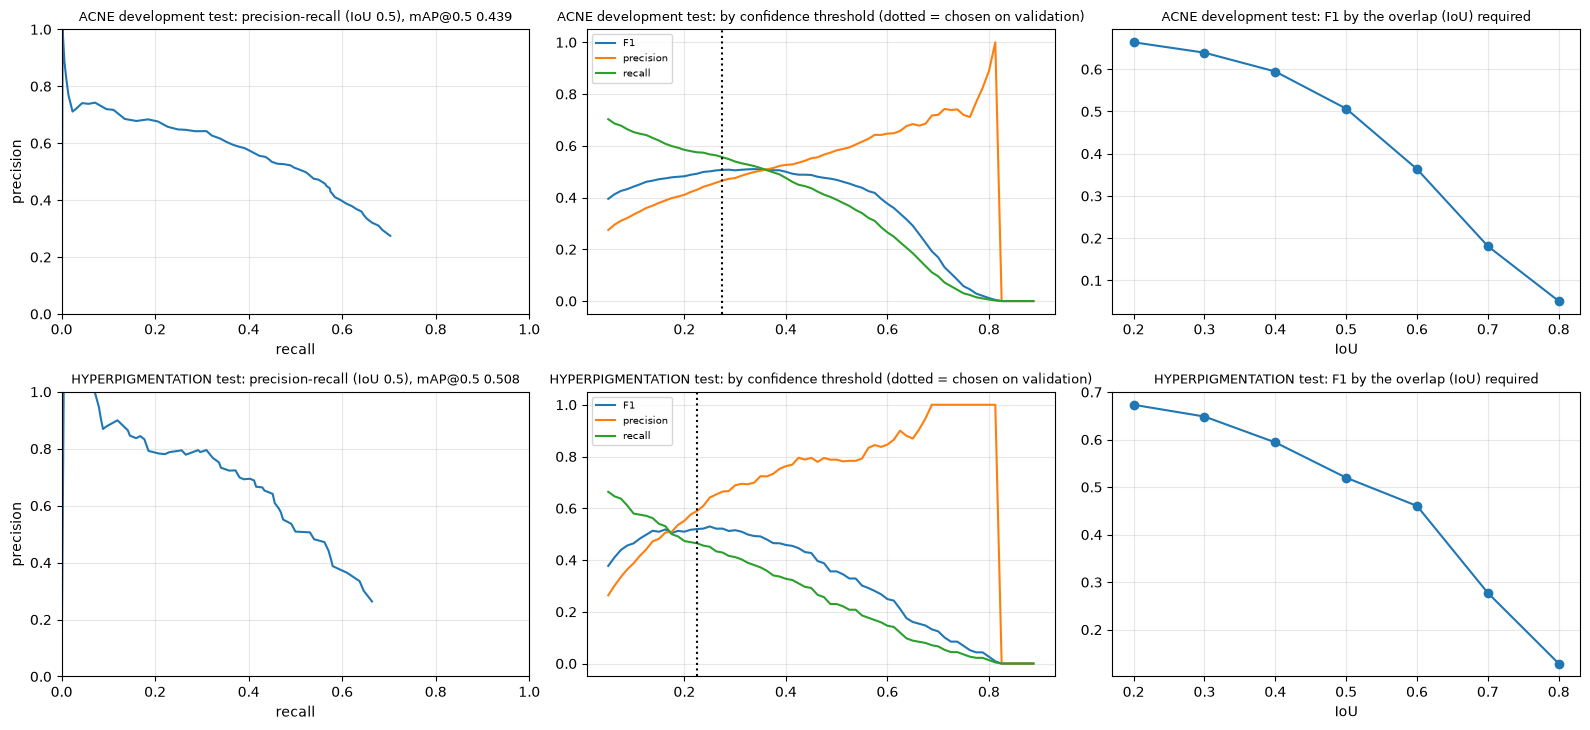

Detection 'confusion' at the chosen threshold (a detector has no true negatives, so the counts are found boxes (TP), false boxes (FP) and missed boxes (FN)): see the columns found_TP / false_boxes_FP / missed_FN in the tables above.


In [17]:
fig, ax = plt.subplots(2, 3, figsize=(16, 7.4))
for row, (name, Rr, Ss) in enumerate((("ACNE development test", RA if "RA" in globals() else None, SA if "SA" in globals() else None), ("HYPERPIGMENTATION test", RH if "RH" in globals() else None, SH if "SH" in globals() else None))):
    if Rr is None: ax[row, 0].text(0.5, 0.5, "MISSING", ha="center"); continue
    cs = np.arange(0.05, 0.9, 0.0125); pr_ = [at_conf(Ss, c) for c in cs]
    ax[row, 0].plot([x[1] for x in pr_], [x[0] for x in pr_]); ax[row, 0].set_title("%s: precision-recall (IoU 0.5), mAP@0.5 %.3f" % (name, Ss["AP50"]), fontsize=9); ax[row, 0].set_xlabel("recall"); ax[row, 0].set_ylabel("precision"); ax[row, 0].set_xlim(0, 1); ax[row, 0].set_ylim(0, 1); ax[row, 0].grid(alpha=.3)
    ax[row, 1].plot(cs, [x[2] for x in pr_], label="F1"); ax[row, 1].plot(cs, [x[0] for x in pr_], label="precision"); ax[row, 1].plot(cs, [x[1] for x in pr_], label="recall"); ax[row, 1].axvline(Rr["thr"], color="k", ls=":"); ax[row, 1].set_title(name + ": by confidence threshold (dotted = chosen on validation)", fontsize=9); ax[row, 1].legend(fontsize=7); ax[row, 1].grid(alpha=.3)
    iouf = f1_by_iou(Rr["fused_test"], Rr["test_dir"], Rr["thr"]); ax[row, 2].plot(list(iouf), list(iouf.values()), "o-"); ax[row, 2].set_title(name + ": F1 by the overlap (IoU) required", fontsize=9); ax[row, 2].set_xlabel("IoU"); ax[row, 2].grid(alpha=.3)
plt.tight_layout(); plt.show()
print("Detection 'confusion' at the chosen threshold (a detector has no true negatives, so the counts are found boxes (TP), false boxes (FP) and missed boxes (FN)): see the columns found_TP / false_boxes_FP / missed_FN in the tables above.")

### 7.4 Sample predictions on test photos (green = the researcher's boxes, red = model boxes above the threshold)

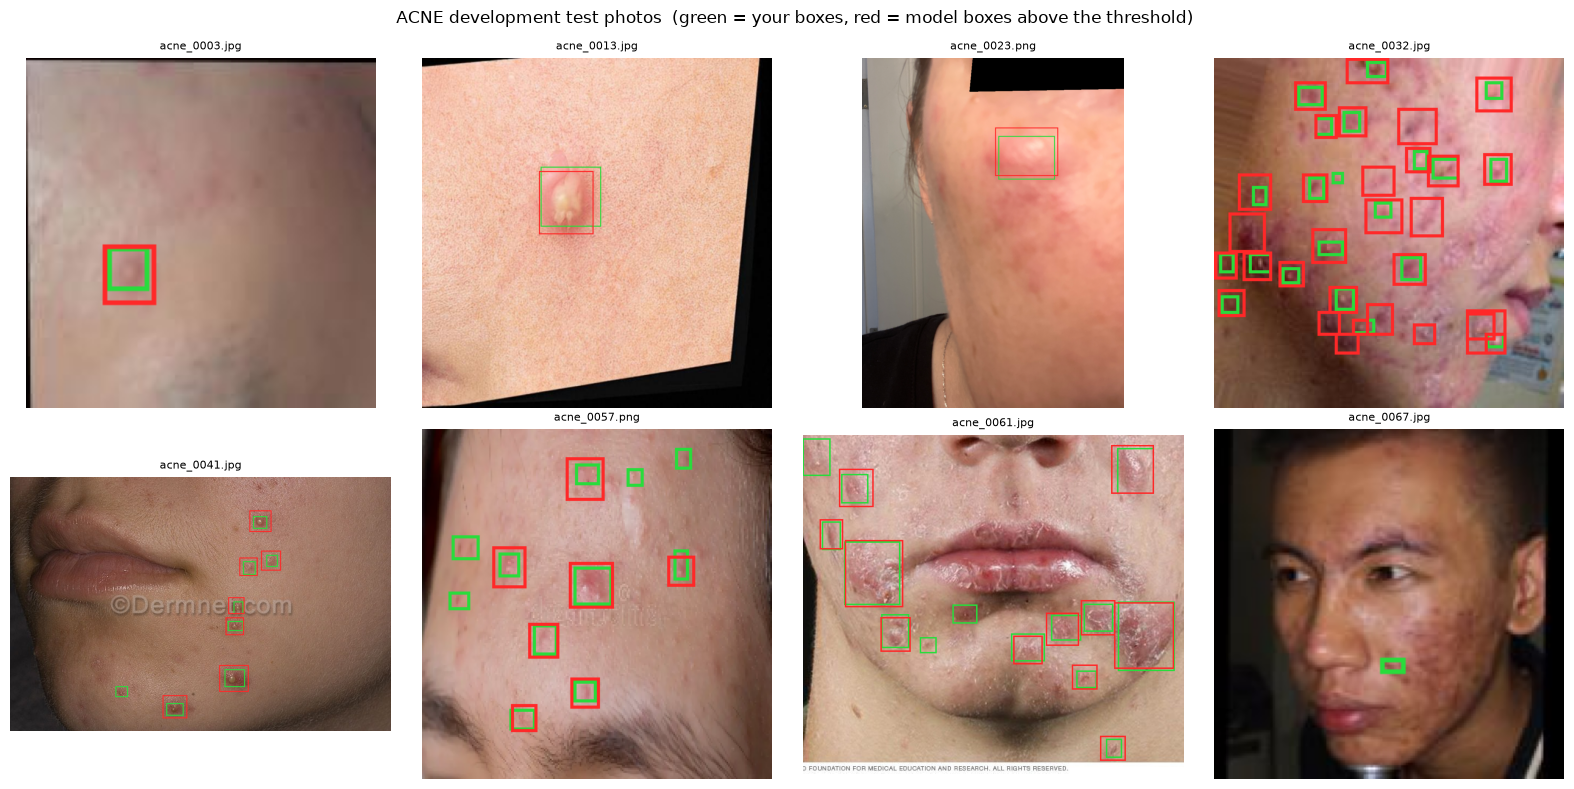

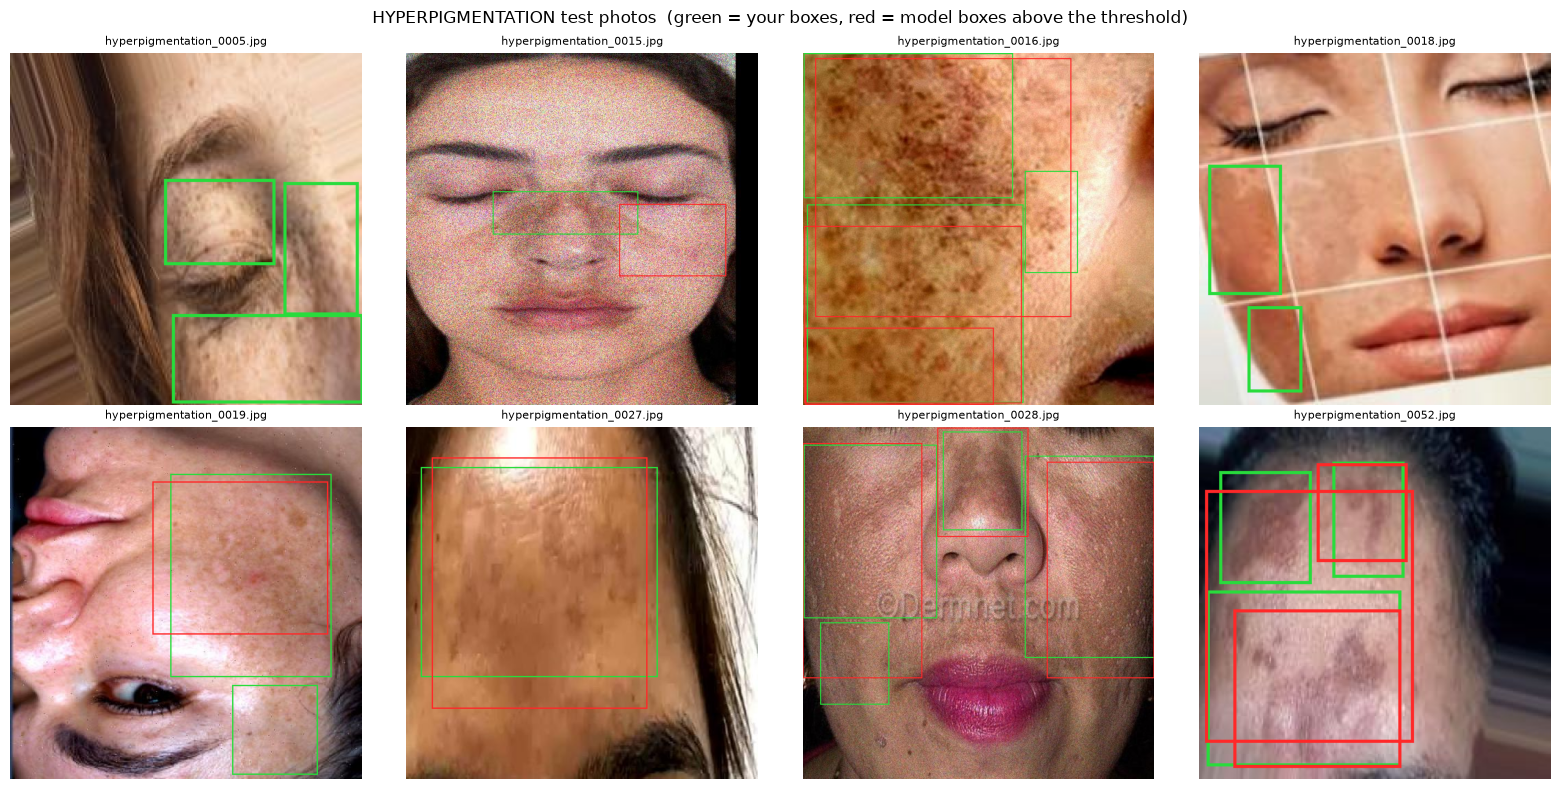

In [18]:
if "RA" in globals():
    names = [p.name for p in images_of(ACNE_DS / "test")][:8]; show_examples(RA["fused_test"], ACNE_DS / "test", RA["thr"], names, title="ACNE development test photos")
if "RH" in globals():
    names = [p.name for p in images_of(EXP / "data" / "hyp_v2_test")][:8]; show_examples(RH["fused_test"], EXP / "data" / "hyp_v2_test", RH["thr"], names, title="HYPERPIGMENTATION test photos")

## 8. What is missing or limited (stated, not filled in)

In [19]:
checks = [
    ("Weights of the superseded experiment runs (deleted on 2026-10-15; per-epoch records and registry rows kept)", None),
    ("SHA-256 of the installed model files recorded at export time (only the acne main file has one)", None),
    ("A signed or tamper-proof timestamp: all dates here are file-system and log timestamps", None),
]
for what, _ in checks: print("-", what)
print()
for desc, p in (("acne final run: results.png of seed 123", ACNE_SEEDS[123] / "results.png"), ("acne final run: confusion matrix of seed 123", ACNE_SEEDS[123] / "confusion_matrix.png"), ("acne final run: DEPLOYMENT_SUMMARY.md", ACNE_RUN / "DEPLOYMENT_SUMMARY.md"),
                ("acne final run: bootstrap.json", ACNE_RUN / "logs" / "bootstrap.json"), ("acne final run: leak_check.csv", ACNE_RUN / "logs" / "leak_check.csv"), ("hyperpigmentation final run: results.png", HYP_RUNS[42] / "results.png"),
                ("experiment registry EXPERIMENTS.csv", EXP / "EXPERIMENTS.csv"), ("training backup folder", Path("/mnt/c/Users/Bautista/Documents/PrecisionSkin_Training_Backup")), ("results table in the repository docs", REPO / "docs" / "RESULTS_FOR_PAPER.md"), ("executed acne final-training notebook with console output (copy)", REPO / "acne" / "evidence" / "Pipeline V5 - Lesion Detector__EXECUTED_by_researcher_2026-10-10.ipynb")):
    print("%-8s %s  (%s)" % ("present" if Path(p).exists() else "MISSING", desc, fdate(p)))
print("\nThings that were recorded by memory of the working session and are NOT in a file: who launched which run (table in section 1 is from the project working records).")
print("Missing records detected automatically while this notebook ran:", len(MISSING), "(the known gaps listed above are stated separately)"); [print("  -", m) for m in MISSING]

- Weights of the superseded experiment runs (deleted on 2026-10-15; per-epoch records and registry rows kept)
- SHA-256 of the installed model files recorded at export time (only the acne main file has one)
- A signed or tamper-proof timestamp: all dates here are file-system and log timestamps

present  acne final run: results.png of seed 123  (2026-10-10 22:32)
present  acne final run: confusion matrix of seed 123  (2026-10-10 22:32)
present  acne final run: DEPLOYMENT_SUMMARY.md  (2026-10-10 22:35)
present  acne final run: bootstrap.json  (2026-10-10 22:33)
present  acne final run: leak_check.csv  (2026-10-10 20:57)
present  hyperpigmentation final run: results.png  (2026-10-13 13:42)
present  experiment registry EXPERIMENTS.csv  (2026-10-13 22:25)
present  training backup folder  (2026-10-13 14:15)
present  results table in the repository docs  (2026-10-15 22:05)
present  executed acne final-training notebook with console output (copy)  (2026-10-16 14:41)

Things that were recorded 

[]

**Other limits that apply to the results themselves (also stated in the thesis text):** one annotator; the acne development test set influenced some earlier decisions (which is why an independent set and a fresh test set were made); the hyperpigmentation scores are under the redefined box rule v2 and are not comparable with scores under the first rule; the fresh acne test has only 36 photos with acne; both detectors put boxes on a share of clear-skin photos; the detectors propose candidate lesions and are not a diagnosis.

## 9. How anyone can check these records themselves
Open a WSL terminal and run these commands. They read files only.
```
ls -l ~/PrecisionSkinV1/runs/lesion_acne_boxed_only/models/seed_123/        # run folder: args.yaml, results.csv, weights, plots, with dates
head -3 ~/PrecisionSkinV1/runs/lesion_acne_boxed_only/models/seed_123/results.csv
column -s, -t < ~/PrecisionSkinV1/lesion_experiments/EXPERIMENTS.csv | head   # the experiment registry
sha256sum /mnt/c/Users/Bautista/source/repos/SkinDevApp/SkinDevApp/Model/lesion_detector_*.onnx
git -C /mnt/c/Users/Bautista/source/repos/SkinDevApp log --format='%h %ad %s' --date=short | head -20
```
The box tool's `labeling_log.csv` files are in each labelling folder under `Downloads/PrecisionSkin/Acne_Boxing` and `Hyperpigmentation_Boxing`. The panel may ask the researcher to open the box tool on a few photos to show how boxing is done.